# LogScope - Week 3 and Week 5 (OFFLINE research evaluation)

## tl;dr

On the held-out 240-minute **simulated** test block (seed 97), multivariate Robust Z (F1 0.9796), K-Means (0.9836), DBSCAN (0.9717) and Isolation Forest (0.9277) outperform the volume-only baseline (F1 0.0). They are **not** live HTTP detection scores. A different synthetic generator shows significantly weaker IF generalization. Do not omit the second experiment in a teacher presentation.

## Context and methods

- The unit of analysis is a **minute window**, not a network flow or a raw HTTP request.
- Five distinct scenario seeds: train 11/23/42, calibrate 71, held-out test 97. Labels never enter model features.
- Models train on normal-labelled training minutes only; score thresholds use validation normals only.
- Methods: B0 volume only, B0 multivariate Robust Z, M1 K-Means distance, M1 DBSCAN core distance, B1 Isolation Forest.
- Primary target: validation normal FPR 5%; 10% is a predeclared sensitivity analysis.
- The second five-seed experiment uses a *different offline simulator*, not a claim of real deployment generalization.

In [1]:
from pathlib import Path
import os,sys
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
if not (root/'backend'/'week5_verified_compare.py').is_file() and (root/'LogScope'/'backend'/'week5_verified_compare.py').is_file():
    root=root/'LogScope'
if not (root/'backend'/'week5_verified_compare.py').is_file():
    raise FileNotFoundError('Run this notebook with the LogScope project as working directory (or unzip project first).')
os.chdir(root)
sys.path.insert(0,str(root))
print('Project:',root)


Project: /mnt/data/logscope_delivery_work/base/LogScope


## Data audit

In [2]:
f=pd.read_csv('datasets/ana/logscope_ana_1200_pencere_ozellikleri.csv')
m=pd.read_csv('datasets/ana/logscope_ana_dakika_etiketleri.csv')
print('Minute features:',f.shape,'Labels:',m.shape)
assert f.minute_start_utc.nunique()==len(f)==1200
assert m.minute_start_utc.nunique()==len(m)==1200
print(pd.crosstab([m.seed,m.split],m.ground_truth).to_string())


Minute features: (1200, 11) Labels: (1200, 7)
ground_truth     anomaly  normal
seed split                      
11   train           120     120
23   train           120     120
42   train           120     120
71   validation      120     120
97   test            120     120


## Results: execute reproducible pipeline

In [3]:
from scripts.run_week3_and_week5_verified import main
summary=main([])


             model      f1  recall     fpr  balanced_accuracy
         B0_volume 0.00000 0.00000 0.05000            0.47500
   B0_multivariate 0.97959 1.00000 0.04167            0.97917
         M1_KMeans 0.98361 1.00000 0.03333            0.98333
         M1_DBSCAN 0.97166 1.00000 0.05833            0.97083
B1_IsolationForest 0.92766 0.90833 0.05000            0.92917
Saved to /mnt/data/logscope_delivery_work/base/LogScope/reports/hafta5/iyilestirilmis_karsilastirma


## Fixed held-out results and attack families

In [4]:
out=Path('reports/hafta5/iyilestirilmis_karsilastirma')
p=pd.read_csv(out/'holdout_seed97_metrics.csv')
families=pd.read_csv(out/'holdout_attack_family_recall.csv')
display(p[p.fpr_target==.05][['model','precision','recall','f1','fpr','balanced_accuracy','mcc','tn','fp','fn','tp']].reset_index(drop=True))
display(families.pivot(index='scenario',columns='model',values='recall').round(3))


,model,precision,recall,f1,fpr,balanced_accuracy,mcc,tn,fp,fn,tp
0,B0_volume,0.00000,0.00000,0.00000,0.05000,0.47500,-0.16013,114,6,120,0
1,B0_multivariate,0.96000,1.00000,0.97959,0.04167,0.97917,0.95917,115,5,0,120
2,M1_KMeans,0.96774,1.00000,0.98361,0.03333,0.98333,0.96720,116,4,0,120
3,M1_DBSCAN,0.94488,1.00000,0.97166,0.05833,0.97083,0.94327,113,7,0,120
4,B1_IsolationForest,0.94783,0.90833,0.92766,0.05000,0.92917,0.85908,114,6,11,109


model,B0_multivariate,B0_volume,B1_IsolationForest,M1_DBSCAN,M1_KMeans
scenario,,,,,
anomaly_5xx,1.0,0.0,1.000,1.0,1.0
anomaly_latency,1.0,0.0,1.000,1.0,1.0
anomaly_login_fail,1.0,0.0,1.000,1.0,1.0
anomaly_rare_route,1.0,0.0,0.633,1.0,1.0


## Second offline simulator and ablation checks

In [5]:
repeats=pd.read_csv(out/'five_seed_summary.csv')
ablation=pd.read_csv(out/'ablation_no_rare_route.csv')
display(repeats[repeats.fpr_target==.05].reset_index(drop=True))
display(ablation[ablation.fpr_target==.05][['model','f1','recall','fpr']].reset_index(drop=True))


,model,fpr_target,f1_mean,f1_std,recall_mean,fpr_mean,balanced_accuracy_mean
0,B0_volume,0.05,0.000000,0.000000,0.000000,0.056666,0.471666
1,B0_multivariate,0.05,0.985568,0.008904,0.971666,0.000000,0.985834
2,M1_KMeans,0.05,0.974826,0.003316,1.000000,0.051666,0.974166
3,M1_DBSCAN,0.05,0.960936,0.014042,1.000000,0.081664,0.959164
4,B1_IsolationForest,0.05,0.239816,0.074372,0.146666,0.061666,0.542500


,model,f1,recall,fpr
0,B0_volume,0.00000,0.00000,0.05000
1,B0_multivariate,0.89189,0.82500,0.02500
2,M1_KMeans,0.84259,0.75833,0.04167
3,M1_DBSCAN,0.86111,0.77500,0.02500
4,B1_IsolationForest,0.72449,0.59167,0.04167


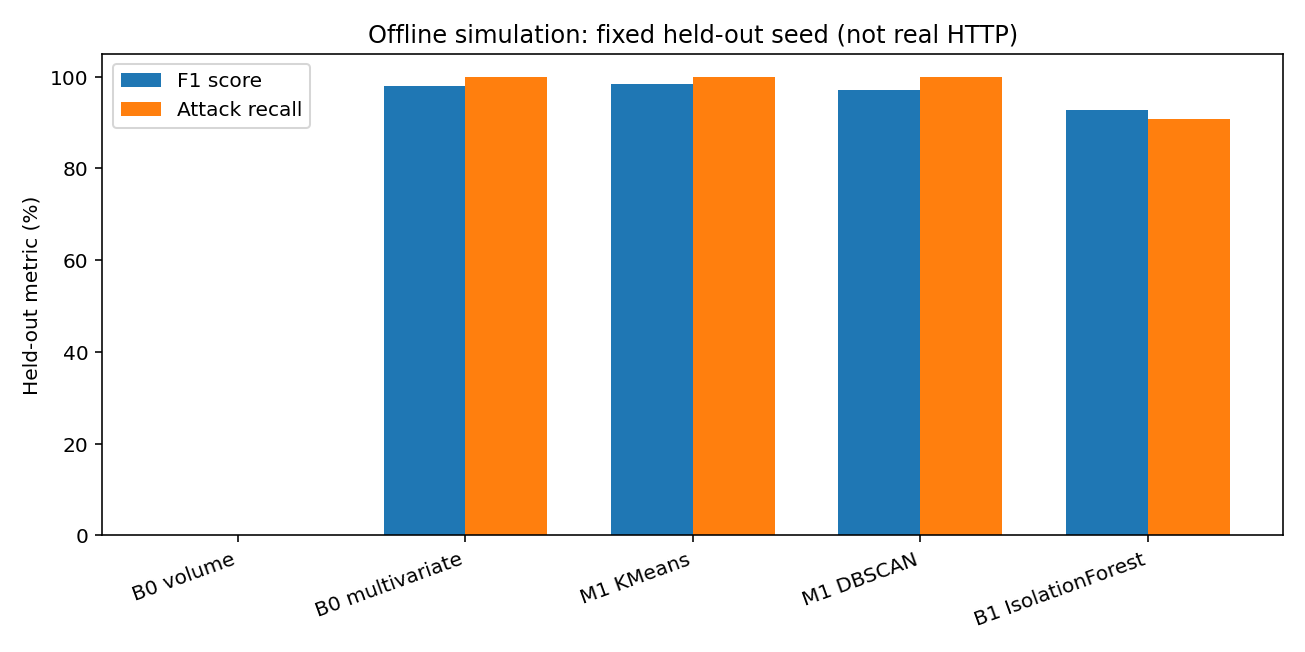

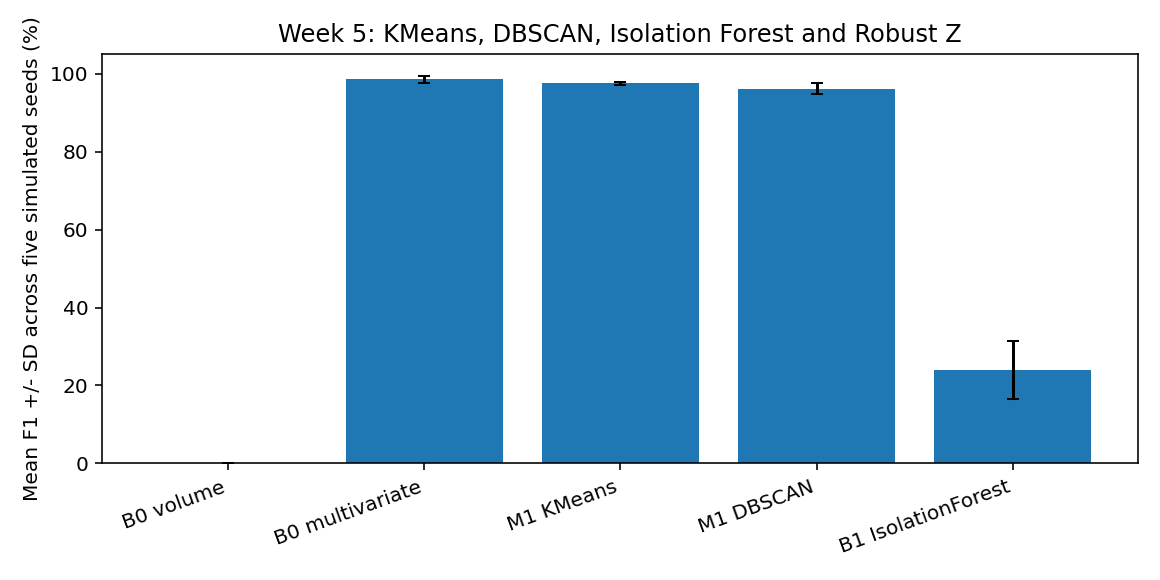

In [6]:
display(Image(filename=str(out/'01_holdout_f1_recall.png')))
display(Image(filename=str(out/'02_five_seed_comparison.png')))


## Takeaways and acceptance status

The old B0 volume-only baseline does not observe the signals (errors, latency, rare routes, failed logins) that define much of the simulation; its F1 = 0 must remain in the report. The multivariate baseline and K-Means/DBSCAN are strong on this source, yet significant performance reduction follows removal of rare-route features. IF scores fall sharply on the alternative offline generator; this is evidence of transfer instability.

**Verified here:** reproducible local dataset processing, training/validation/test isolation checks, five repeated offline tests, React static route/JSX checks and API integration tests. **Not yet verified:** actual Django/Locust request acceptance, full React browser/build QA, live PostgreSQL migrations or real-world HTTP recall/F1. These results should not be presented as field deployment accuracy.